<a href="https://colab.research.google.com/github/iretomiwasoladoye-spec/northbridge-admissions-model/blob/main/PDM_Summative.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Load Admission Data - Solution Development

The admission data was loaded using pandas, with NumPy used for handling missing values and Matplotlib/Seaborn used for visualisation. Recruiter A was supplied as a CSV file and Recruiter B as an Excel workbook, so read_csv() and read_excel() were used respectively. During import, keep_default_na=False prevented pandas from treating the valid disability category “None” as a missing value, while na_values=[""] ensured genuinely empty cells were still recognised as missing. Initial checks found that Recruiter B contained four missing values and nine records with abbreviated labels such as “M”, “F”, “A”, “Soc”, “S” and “I”. The unambiguous abbreviations were converted to their full labels to make both datasets consistent, while the ambiguous value “I” was treated as missing rather than guessed. In addition, the disability category “Mental” was renamed to “Mental Health” in both datasets to match the accepted value specified in the brief. A recruiter identifier column was then added to each dataset before they were combined using pd.concat(), producing a single dataset of 8,000 applications.

In [1]:
# Libraries
import pandas as pd                # pandas: works with tables of data (called DataFrames)
import numpy as np                 # numpy: number helpers, also used for "missing" values
import matplotlib.pyplot as plt    # matplotlib: basic charts
import seaborn as sns              # seaborn: nicer statistical charts built on matplotlib

# Load the two recruiter files into tables
# keep_default_na=False stops pandas turning the text "None" into a missing value
# na_values=[""] still treats truly empty cells as missing
df_a = pd.read_csv('recruiter_A.csv', keep_default_na=False, na_values=[""])
df_b = pd.read_excel('recruiter_B.xlsx', keep_default_na=False, na_values=[""])

# Check how many rows and columns each file has
print(df_a.shape)
print(df_b.shape)

(4000, 12)
(4000, 12)


In [2]:
# Show the first 5 rows of each file
display(df_a.head())
display(df_b.head())

,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome
0,A00001,59.1,59.3,2.94,State,Humanities,47.3,0,Female,Other,None,1
1,A00002,80.0,78.0,3.60,State,Humanities,49.9,1,Male,Mixed,None,1
2,A00003,72.8,60.4,3.31,State,Arts,145.9,0,Male,Asian,None,1
3,A00004,54.9,60.7,3.52,State,STEM,63.1,0,Female,White,None,1
4,A00005,64.2,56.8,2.99,State,Arts,175.9,1,Male,Black,None,1


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome
0,B00001,61.3,76.1,3.80,State,Arts,95.6,0,Female,Other,None,0
1,B00002,56.6,60.9,2.81,State,Humanities,80.9,0,Female,Other,None,1
2,B00003,72.4,73.5,3.56,Independent,STEM,70.5,1,Male,White,None,1
3,B00004,76.3,75.4,2.46,State,Social Sciences,118.4,0,Male,Other,None,1
4,B00005,65.1,57.8,3.75,State,Humanities,88.3,1,Female,White,Learning,1


In [3]:
# Show the column types and how many values each column actually has
df_a.info()
print()      # blank line between the two outputs
df_b.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   student_id                4000 non-null   object 
 1   prior_attainment_score    4000 non-null   float64
 2   admissions_test_score     4000 non-null   float64
 3   personal_statement_score  4000 non-null   float64
 4   school_type               4000 non-null   object 
 5   intended_subject_area     4000 non-null   object 
 6   distance_from_campus_km   4000 non-null   float64
 7   first_generation_student  4000 non-null   int64  
 8   gender                    4000 non-null   object 
 9   ethnicity                 4000 non-null   object 
 10  disability_status         4000 non-null   object 
 11  admission_outcome         4000 non-null   int64  
dtypes: float64(4), int64(2), object(6)
memory usage: 375.1+ KB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 ent

In [4]:
# The text columns that should only contain a fixed set of labels
cat_cols = ["school_type", "intended_subject_area", "gender", "ethnicity", "disability_status"]

# For each column, list the different labels used in file A and in file B
for col in cat_cols:
    print(col)
    print("  A:", sorted(df_a[col].dropna().unique()))
    print("  B:", sorted(df_b[col].dropna().unique()))

school_type
  A: ['Independent', 'International', 'State']
  B: ['I', 'Independent', 'International', 'S', 'State']
intended_subject_area
  A: ['Arts', 'Humanities', 'STEM', 'Social Sciences']
  B: ['A', 'Arts', 'Humanities', 'STEM', 'Soc', 'Social Sciences']
gender
  A: ['Female', 'Male', 'Other']
  B: ['F', 'Female', 'M', 'Male', 'Other']
ethnicity
  A: ['Asian', 'Black', 'Mixed', 'Other', 'White']
  B: ['Asian', 'Black', 'Mixed', 'Other', 'White']
disability_status
  A: ['Learning', 'Mental', 'None', 'Physical']
  B: ['Learning', 'Mental', 'None', 'Physical']


In [5]:
# Fix B's short labels so they match A and the brief
df_b['gender'] = df_b['gender'].replace({'M': 'Male', 'F': 'Female'})
df_b['intended_subject_area'] = df_b['intended_subject_area'].replace({'A': 'Arts', 'Soc': 'Social Sciences'})

# "S" clearly means State.
# "I" could be Independent or International, so we do not guess: we mark it as missing (np.nan)
df_b['school_type'] = df_b['school_type'].replace({'S': 'State', 'I': np.nan})

# Both files say "Mental" but the brief says "Mental Health"
df_a['disability_status'] = df_a['disability_status'].replace({'Mental': 'Mental Health'})
df_b['disability_status'] = df_b['disability_status'].replace({'Mental': 'Mental Health'})

In [6]:
# Record which recruiter each row came from
df_a['recruiter'] = 'A'
df_b['recruiter'] = 'B'

# Stack the two tables on top of each other into one table
combined = pd.concat([df_a, df_b], ignore_index=True)

# Check the result
print(combined.shape)
print(combined['recruiter'].value_counts())
print("Duplicate student_ids:", combined['student_id'].duplicated().sum())

(8000, 13)
recruiter
A    4000
B    4000
Name: count, dtype: int64
Duplicate student_ids: 0


### Descriptive Analysis

In [7]:
# Count the empty (missing) cells in each column of the combined table
combined.isna().sum()

,0
student_id,0
prior_attainment_score,0
admissions_test_score,0
personal_statement_score,0
school_type,2
intended_subject_area,1
distance_from_campus_km,1
first_generation_student,0
gender,0
ethnicity,0


In [8]:
# Use student_id as the row label (index) instead of 0, 1, 2...
combined = combined.set_index('student_id')

# Check: every ID should be unique, and the first rows should now be labelled by ID
print("Index is unique:", combined.index.is_unique)
combined.head()

Index is unique: True


,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome,recruiter
student_id,,,,,,,,,,,,
A00001,59.1,59.3,2.94,State,Humanities,47.3,0,Female,Other,None,1,A
A00002,80.0,78.0,3.60,State,Humanities,49.9,1,Male,Mixed,None,1,A
A00003,72.8,60.4,3.31,State,Arts,145.9,0,Male,Asian,None,1,A
A00004,54.9,60.7,3.52,State,STEM,63.1,0,Female,White,None,1,A
A00005,64.2,56.8,2.99,State,Arts,175.9,1,Male,Black,None,1,A


In [9]:
# # Expected ranges: the brief states 0 to 100 for the first two scores, but only "typically" 1 to 5 for the personal statement
limits = {
    "prior_attainment_score": (0, 100),
    "admissions_test_score": (0, 100),
    "personal_statement_score": (1, 5),
}

# For each score column, count the rows below the minimum and above the maximum
for col, (low, high) in limits.items():
    below = (combined[col] < low).sum()
    above = (combined[col] > high).sum()
    print(col, "| below", low, ":", below, "| above", high, ":", above)

prior_attainment_score | below 0 : 0 | above 100 : 4
admissions_test_score | below 0 : 0 | above 100 : 10
personal_statement_score | below 1 : 15 | above 5 : 118


In [10]:
# Attainment and test: the brief says 0 to 100, so values above 100 are impossible. Cap them at 100.
for col in ["prior_attainment_score", "admissions_test_score"]:
    combined[col] = combined[col].clip(upper=100)

# Personal statement: the brief only says "typically" 1 to 5, so we keep the values
# and flag the rows outside that range instead of changing them
combined['ps_outside_1_5'] = (combined['personal_statement_score'] < 1) | (combined['personal_statement_score'] > 5)

# One score is below 0, which cannot be a real evaluation, so we cap it at 0
combined['personal_statement_score'] = combined['personal_statement_score'].clip(lower=0)

# Check
print("Personal statement rows flagged:", combined['ps_outside_1_5'].sum())
print(combined[["prior_attainment_score", "admissions_test_score", "personal_statement_score"]].agg(['min', 'max']))

Personal statement rows flagged: 133
     prior_attainment_score  admissions_test_score  personal_statement_score
min                    32.0                   12.5                      0.00
max                   100.0                  100.0                      6.45


In [11]:
# Find the rows that have at least one missing value, and look at them first
missing_rows = combined[combined.isna().any(axis=1)]
print(missing_rows.shape[0], "rows have a missing value")
display(missing_rows)

5 rows have a missing value


,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome,recruiter,ps_outside_1_5
student_id,,,,,,,,,,,,,
B00297,69.4,70.0,3.82,NaN,STEM,305.1,0,Female,Asian,None,1,B,False
B03716,75.9,78.7,4.03,State,STEM,NaN,0,Male,Mixed,None,0,B,False
B03812,62.0,74.4,1.69,State,NaN,108.0,1,Female,White,None,0,B,False
B03843,61.9,55.4,4.91,Independent,Humanities,75.9,0,Male,White,NaN,0,B,False
B03848,61.3,57.4,3.86,NaN,Humanities,89.3,1,Male,Other,None,1,B,False


In [12]:
# Work on a copy so combined stays as the record of the data before filling
clean_df = combined.copy()

# Text columns: label the gaps "Not recorded" instead of guessing an answer
for col in ["school_type", "intended_subject_area", "disability_status"]:
    clean_df[col] = clean_df[col].fillna("Not recorded")

# distance_from_campus_km has one empty cell. We leave it empty rather than invent a number.
# Check: only that one gap should remain, and all 8,000 applicants should still be there
print(clean_df.isna().sum().sum(), "missing value left")
print(clean_df.shape)

1 missing value left
(8000, 13)


Before analysis, several data quality issues were addressed. Four attainment scores and ten test scores above 100 were capped at 100 because values above the maximum possible score are invalid. One negative personal statement score was capped at 0, since an evaluation cannot be negative. Personal statement scores outside the usual 1-5 range were retained because the specification described this range as typical rather than mandatory; instead, the 133 affected records were flagged for reference. Missing text values were labelled as “Not recorded”, except for one missing distance value, which was left blank to avoid inventing data.

## Exploratory Data Analysis

In [13]:
# 1. Number of records (applicants)
print("Number of records:", len(clean_df))

Number of records: 8000


In [14]:
# 2. Percentage of applicants offered a place
# admission_outcome is 1 (offer) or 0 (no offer), so its average is the share who got an offer
offer_pct = clean_df['admission_outcome'].mean() * 100
print(f"Percentage offered a place: {offer_pct:.1f}%")


Percentage offered a place: 60.6%


In [15]:
#3. Offers by gender
by_gender = clean_df.groupby('gender')['admission_outcome'].agg(applicants='count', offers='sum')

# Percentage of all offers that went to each gender
by_gender['pct_of_all_offers'] = (by_gender['offers'] / by_gender['offers'].sum() * 100).round(1)

# Percentage of all applicants who are each gender, for comparison
by_gender['pct_of_all_applicants'] = (by_gender['applicants'] / by_gender['applicants'].sum() * 100).round(1)

print(by_gender)

        applicants  offers  pct_of_all_offers  pct_of_all_applicants
gender                                                              
Female        4028    2453               50.6                   50.3
Male          3808    2307               47.6                   47.6
Other          164      90                1.9                    2.1


In [16]:
# Applications and offers for each recruiter
by_recruiter = clean_df.groupby('recruiter')['admission_outcome'].agg(applications='count', offers='sum')

# Offer rate = offers divided by applications, as a percentage
by_recruiter['offer_rate_pct'] = (by_recruiter['offers'] / by_recruiter['applications'] * 100).round(1)

print(by_recruiter)

           applications  offers  offer_rate_pct
recruiter                                      
A                  4000    2395            59.9
B                  4000    2455            61.4


In [17]:
# Mean and median of the three numeric columns the brief asks for
numeric_cols = ["prior_attainment_score", "admissions_test_score", "distance_from_campus_km"]
print(clean_df[numeric_cols].agg(['mean', 'median']).round(1))

        prior_attainment_score  admissions_test_score  distance_from_campus_km
mean                      70.0                   65.2                     89.5
median                    70.0                   65.4                     79.5


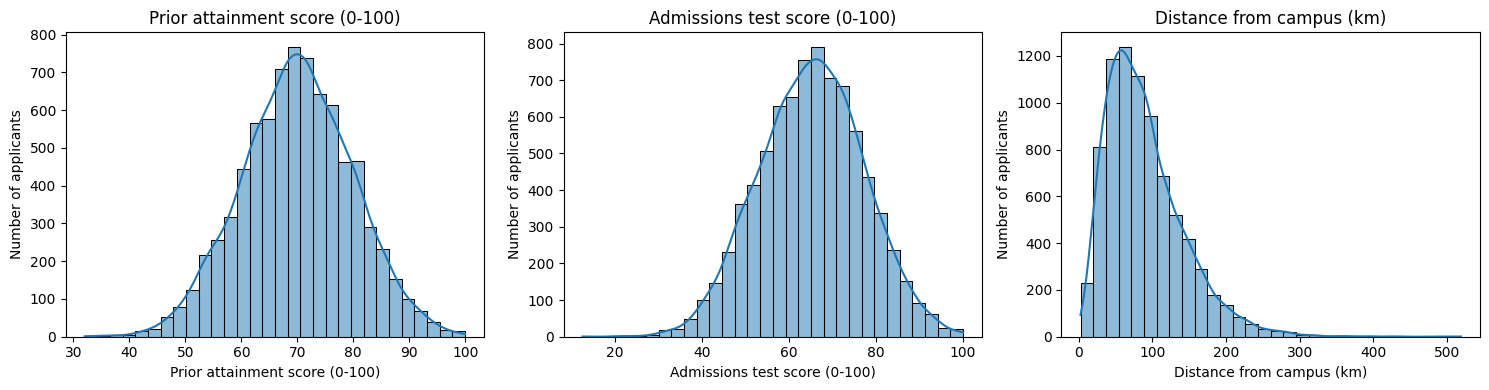

In [18]:
# Histograms: how many applicants fall into each range of values
fig, axes = plt.subplots(1, 3, figsize=(15, 4))    # one row, three charts side by side

labels = {
    "prior_attainment_score": "Prior attainment score (0-100)",
    "admissions_test_score": "Admissions test score (0-100)",
    "distance_from_campus_km": "Distance from campus (km)",
}

for ax, col in zip(axes, numeric_cols):
    sns.histplot(clean_df[col], bins=30, kde=True, ax=ax)   # bars plus a smooth line
    ax.set_title(labels[col])
    ax.set_xlabel(labels[col])
    ax.set_ylabel("Number of applicants")

plt.tight_layout()    # stops the charts overlapping
plt.show()

In [19]:
# Summary statistics for the three numeric columns: count, mean, spread (std), min, max
# and the 25%, 50% (median) and 75% points, to back up the histograms above
clean_df[numeric_cols].describe().round(1)

,prior_attainment_score,admissions_test_score,distance_from_campus_km
count,8000.0,8000.0,7999.0
mean,70.0,65.2,89.5
std,9.9,12.0,52.8
min,32.0,12.5,2.4
25%,63.4,57.0,51.0
50%,70.0,65.4,79.5
75%,76.7,73.4,117.2
max,100.0,100.0,519.1


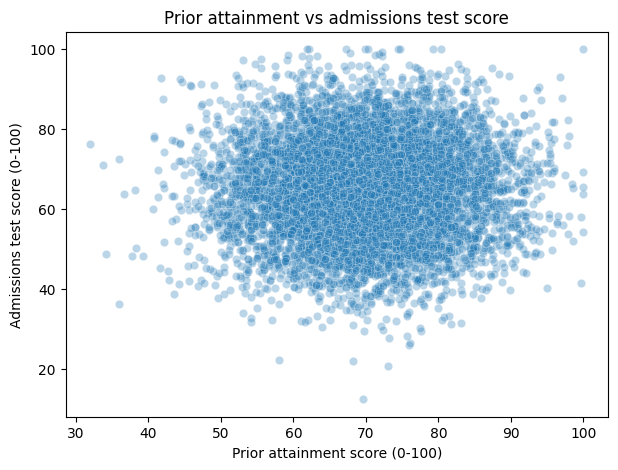

Correlation: 0.02


In [20]:
# Scatter plot: each dot is one applicant
plt.figure(figsize=(7, 5))
sns.scatterplot(data=clean_df, x="prior_attainment_score", y="admissions_test_score", alpha=0.3)
plt.title("Prior attainment vs admissions test score")
plt.xlabel("Prior attainment score (0-100)")
plt.ylabel("Admissions test score (0-100)")
plt.show()

# Correlation: a single number from -1 to 1 showing how strongly the two move together
corr = clean_df["prior_attainment_score"].corr(clean_df["admissions_test_score"])
print("Correlation:", round(corr, 2))

In [21]:
# Average of each numeric column for applicants who got an offer (1) and those who did not (0)
score_cols = ["prior_attainment_score", "admissions_test_score", "personal_statement_score", "distance_from_campus_km"]
print(clean_df.groupby('admission_outcome')[score_cols].mean().round(1))

                   prior_attainment_score  admissions_test_score  \
admission_outcome                                                  
0                                    68.8                   63.8   
1                                    70.8                   66.1   

                   personal_statement_score  distance_from_campus_km  
admission_outcome                                                     
0                                       3.2                     89.2  
1                                       3.2                     89.7  


In [22]:
# For each group column: applicants, offers, and the percentage of that group's applicants who got an offer
group_cols = ["school_type", "first_generation_student", "ethnicity", "disability_status", "intended_subject_area"]

for col in group_cols:
    table = clean_df.groupby(col)['admission_outcome'].agg(applicants='count', offers='sum')
    table['pct_of_group_offered'] = (table['offers'] / table['applicants'] * 100).round(1)
    print(table)
    print()    # blank line between tables

               applicants  offers  pct_of_group_offered
school_type                                            
Independent          1957    1169                  59.7
International         834     514                  61.6
Not recorded            2       2                 100.0
State                5207    3165                  60.8

                          applicants  offers  pct_of_group_offered
first_generation_student                                          
0                               5208    3149                  60.5
1                               2792    1701                  60.9

           applicants  offers  pct_of_group_offered
ethnicity                                          
Asian            1597     974                  61.0
Black            1593     993                  62.3
Mixed            1614     985                  61.0
Other            1633     974                  59.6
White            1563     924                  59.1

                   applicants

The final dataset contained 8,000 applications, of which 60.6% received an offer. Attainment and test scores showed approximately bell-shaped distributions, while distance was positively skewed with a long tail extending to around 500 km. Applicants receiving offers had slightly higher average attainment and test scores than those who were rejected, while personal statement scores and distance showed no difference in average values between the two groups. Offer rates across school type, ethnicity, disability status, first-generation status and subject area were generally between 59% and 62% among groups with meaningful numbers. The main exception was the gender category “Other”, which had an offer rate of 54.9%, although this group contained only 164 applicants. The correlation between attainment and test score was 0.02, indicating virtually no relationship between the two measures.

### Modelling

Prepare the features and split the data

In [23]:
from sklearn.model_selection import train_test_split    # scikit-learn: the machine learning library

# The columns the model is allowed to learn from (features) and what it must predict (target)
features = ["prior_attainment_score", "admissions_test_score", "personal_statement_score", "intended_subject_area"]
X = clean_df[features]
y = clean_df["admission_outcome"]

# Split 1: set aside 20% of applicants as the final test set, which is not used until the very end
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Split 2: split the remaining 80% into training (60% of the total) and validation (20% of the total)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

print("Training:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("Offer rate in each set:", round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

Training: (4800, 4) | Validation: (1600, 4) | Test: (1600, 4)
Offer rate in each set: 0.606 0.606 0.606


Train the two models and compare them

In [24]:
# --- Libraries ---
# scikit-learn (sklearn): the main Python library for machine learning. Everything below comes from it.
from sklearn.compose import ColumnTransformer          # applies different preparation steps to different columns (numbers vs text)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# StandardScaler: rescales numbers to a common size so no score dominates because of its scale
# OneHotEncoder: turns a text column (like subject area) into 0/1 columns the model can use
from sklearn.pipeline import Pipeline                  # chains preparation and model into one object, so training and test data are treated identically
from sklearn.linear_model import LogisticRegression    # model 1: simple, and its feature weights can be explained
from sklearn.ensemble import RandomForestClassifier    # model 2: many decision trees voting together, flexible
from sklearn.dummy import DummyClassifier              # a baseline that always predicts the overall offer rate, to show whether the real models learn anything
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
# metrics: functions that score how well the predictions match the real outcomes

# --- Which columns are numbers and which are text ---
model_num_cols = ["prior_attainment_score", "admissions_test_score", "personal_statement_score"]   # numeric features
model_cat_cols = ["intended_subject_area"]                                                          # text feature

# --- Data preparation, written as a function so each model gets its own fresh copy ---
def make_prep():
    # Scale the three scores to a comparable size; turn subject area (text) into 0/1 columns
    return ColumnTransformer([
        ("num", StandardScaler(), model_num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), model_cat_cols),   # handle_unknown="ignore": no error if a new subject appears later
    ])

# --- The three models to compare ---
models = {
    # Baseline: ignores the applicants and always predicts the overall offer rate. Real models must beat this.
    "Baseline (no learning)": Pipeline([("prep", make_prep()), ("model", DummyClassifier(strategy="prior"))]),

    # Model 1: simple. Weighs each feature and gives a probability of an offer.
    "Logistic regression": Pipeline([("prep", make_prep()), ("model", LogisticRegression(max_iter=1000))]),

    # Model 2: flexible. 300 decision trees vote. max_depth and min_samples_leaf stop trees getting
    # too complicated, so the model does not just memorise the training data. random_state makes it repeatable.
    "Random forest": Pipeline([("prep", make_prep()), ("model", RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=20, random_state=42))]),
}

# --- Train each model and score it on the validation set ---
results = []                                           # an empty list to collect each model's scores
for name, model in models.items():                     # repeat the steps below once per model
    model.fit(X_train, y_train)                        # learn from the training set
    prob = model.predict_proba(X_val)[:, 1]            # predicted chance of an offer for each validation applicant
    pred = (prob >= 0.5).astype(int)                   # predict an offer (1) if that chance is 50% or more, otherwise 0
    results.append({
        "Model": name,
        "Log loss": log_loss(y_val, prob),             # our loss function: lower is better, punishes confident wrong predictions
        "Accuracy": accuracy_score(y_val, pred),       # share of applicants predicted correctly
        "Precision": precision_score(y_val, pred),     # of those predicted an offer, the share who really got one
        "Recall": recall_score(y_val, pred),           # of those who really got an offer, the share the model found
        "F1": f1_score(y_val, pred),                   # a single score balancing precision and recall
        "ROC AUC": roc_auc_score(y_val, prob),         # how well offered applicants are ranked above rejected ones (0.5 = random, 1 = perfect)
    })

# --- Put the scores in a table ---
results_df = pd.DataFrame(results).set_index("Model").round(3)
print(results_df)

                        Log loss  Accuracy  Precision  Recall     F1  ROC AUC
Model                                                                        
Baseline (no learning)     0.670     0.606      0.606   1.000  0.755    0.500
Logistic regression        0.663     0.606      0.616   0.926  0.740    0.570
Random forest              0.662     0.597      0.606   0.956  0.742    0.569


# Evaluate the Models

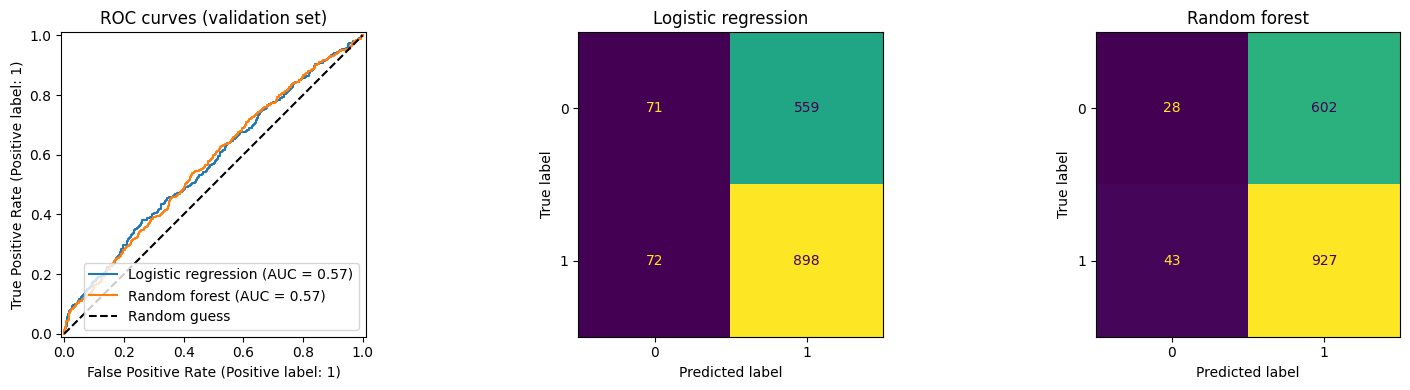

In [25]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay   # ready-made plots for model evaluation

fig, axes = plt.subplots(1, 3, figsize=(16, 4))        # three charts side by side

# Chart 1: ROC curves. The further a curve bends above the dashed diagonal, the better the model ranks applicants
for name in ["Logistic regression", "Random forest"]:
    RocCurveDisplay.from_estimator(models[name], X_val, y_val, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_title("ROC curves (validation set)")
axes[0].legend()

# Charts 2 and 3: confusion matrices. Each box counts applicants: rows are the real outcome, columns the prediction
ConfusionMatrixDisplay.from_estimator(models["Logistic regression"], X_val, y_val, ax=axes[1], colorbar=False)
axes[1].set_title("Logistic regression")
ConfusionMatrixDisplay.from_estimator(models["Random forest"], X_val, y_val, ax=axes[2], colorbar=False)
axes[2].set_title("Random forest")

plt.tight_layout()
plt.show()

In [26]:
# Final evaluation on the test set: applicants the models have never seen
results_test = []
for name, model in models.items():
    prob = model.predict_proba(X_test)[:, 1]           # predicted chance of an offer for each test applicant
    pred = (prob >= 0.5).astype(int)                   # offer (1) if that chance is 50% or more
    results_test.append({
        "Model": name,
        "Log loss": log_loss(y_test, prob),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob),
    })

results_test_df = pd.DataFrame(results_test).set_index("Model").round(3)
print(results_test_df)

                        Log loss  Accuracy  Precision  Recall     F1  ROC AUC
Model                                                                        
Baseline (no learning)     0.670     0.606      0.606   1.000  0.755    0.500
Logistic regression        0.663     0.618      0.620   0.953  0.751    0.576
Random forest              0.663     0.614      0.614   0.980  0.755    0.574


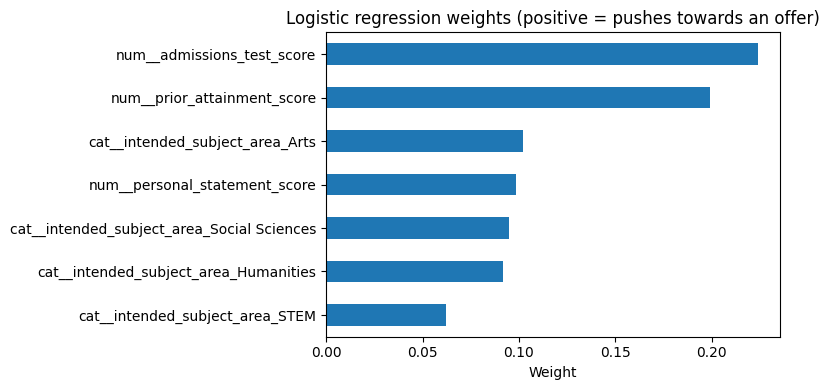

cat__intended_subject_area_STEM               0.062
cat__intended_subject_area_Humanities         0.092
cat__intended_subject_area_Social Sciences    0.095
num__personal_statement_score                 0.099
cat__intended_subject_area_Arts               0.102
num__prior_attainment_score                   0.199
num__admissions_test_score                    0.224
dtype: float64


In [28]:
# Pull the learned weights out of the fitted logistic regression pipeline
logit_pipeline = models["Logistic regression"]                              # the fitted pipeline
model_step = logit_pipeline.named_steps["model"]                            # the logistic regression itself
feature_names = logit_pipeline.named_steps["prep"].get_feature_names_out()  # names after scaling and encoding
weights = pd.Series(model_step.coef_[0], index=feature_names).sort_values()

# Bar chart: a positive weight pushes the prediction towards an offer, a negative one away from it
plt.figure(figsize=(8, 4))
weights.plot(kind="barh")
plt.title("Logistic regression weights (positive = pushes towards an offer)")
plt.xlabel("Weight")
plt.tight_layout()
plt.show()

print(weights.round(3))

# Model Selection & Evaluation
Two models were tested: logistic regression and random forest, alongside a baseline model that always predicted the overall offer rate. The data was split into training (60%), validation (20%) and test (20%) sets, with protected and proxy variables excluded from model training. Performance was primarily evaluated using log loss because it assesses the quality of predicted probabilities and penalises confident incorrect predictions. Accuracy, precision, recall, F1 score and AUC were also reported to provide a broader assessment of performance.

Both models achieved very similar results on the test set and only slightly outperformed the baseline. Logistic regression achieved an accuracy of 0.618, log loss of 0.663 and AUC of 0.576, while the random forest achieved 0.614, 0.663 and 0.574 respectively. By comparison, the baseline achieved an accuracy of 0.606, log loss of 0.670 and AUC of 0.500. These results show that neither model provided a substantial improvement over simply predicting the average offer rate.

As neither model provided a meaningful performance advantage, logistic regression was selected because it is simpler and more transparent. Its predictions can be explained in terms of key factors such as admissions test scores and prior attainment, making it more suitable for a decision-support tool where decisions may need to be justified to applicants and admissions staff. However, both models performed only marginally better than the baseline and, using a 50% decision threshold, tended to predict offers for almost all applicants. This suggests that the models are not reliable enough to be used as an automated shortlisting system and should instead be used only to support human decision-making.

### Fairness Audit

In [27]:
# Use the chosen model (logistic regression) to score every applicant in the test set
final_model = models["Logistic regression"]
prob_test = final_model.predict_proba(X_test)[:, 1]    # predicted chance of an offer

# Shortlist the top 60% of applicants by predicted chance (roughly the real offer rate)
cutoff = np.quantile(prob_test, 0.4)                   # the value 40% of applicants fall below
shortlisted = (prob_test >= cutoff).astype(int)        # 1 = shortlisted, 0 = not

# Attach the protected and proxy columns to the test applicants. These were never given to the model.
audit_cols = ["gender", "ethnicity", "disability_status", "school_type", "first_generation_student"]
audit = clean_df.loc[X_test.index, audit_cols].copy()  # same applicants, matched by ID
audit["shortlisted"] = shortlisted
audit["actually_offered"] = y_test                     # what really happened

# For each group: how many applicants, what share the model shortlists, what share really got an offer
for col in audit_cols:
    table = audit.groupby(col).agg(
        applicants=("shortlisted", "count"),
        pct_shortlisted=("shortlisted", "mean"),
        pct_actually_offered=("actually_offered", "mean"),
    )
    table[["pct_shortlisted", "pct_actually_offered"]] = (table[["pct_shortlisted", "pct_actually_offered"]] * 100).round(1)
    print(table)
    print()

        applicants  pct_shortlisted  pct_actually_offered
gender                                                   
Female         812             59.5                  60.2
Male           757             60.9                  61.3
Other           31             51.6                  54.8

           applicants  pct_shortlisted  pct_actually_offered
ethnicity                                                   
Asian             299             60.5                  61.9
Black             305             59.3                  64.3
Mixed             326             60.4                  59.8
Other             340             59.1                  58.8
White             330             60.6                  58.8

                   applicants  pct_shortlisted  pct_actually_offered
disability_status                                                   
Learning                  150             58.7                  62.7
Mental Health              99             64.6                  66.7
None 

# Fairness Audit Result

A fairness audit was carried out by comparing the proportion of applicants shortlisted by the selected model across demographic groups. Using a shortlist threshold designed to select approximately the top 60% of applicants, most groups had shortlisting rates between about 58% and 65%, suggesting no large differences in outcomes across the majority of categories examined.

The largest difference was observed for the gender category "Other", which had a shortlisting rate of 51.6%. However, this result is based on only 31 applicants in the test set, making it too small to support reliable conclusions. Overall, the audit did not identify substantial disparities between groups, but the findings should be interpreted cautiously because some categories contain limited numbers of applicants.

It is also important to note that similar shortlisting rates do not prove that a model is fair. The model is trained on historical admissions decisions and may therefore reproduce biases that already exist within the data. For this reason, fairness monitoring and human oversight would be required if the model were used in practice.